# Homework 12 — Part 1: LLM optimisation with GPTQ (speed and accuracy comparison)

**Student parameters (standing Step 0 rule):** `SID4 = 2122`, `SEED = 2122`, `HP_ID = 4`

| Item | Value |
|---|---|
| Base LLM | `facebook/opt-125m`, the model used in the Hugging Face GPTQ guide that the assignment links to. The exact revision (commit SHA) is recorded below. |
| Quantisation | Hugging Face `transformers` `GPTQConfig`: 4-bit, group size 128, `desc_act=False`, symmetric, backend GPT-QModel |
| Calibration data | WikiText-2 (`wikitext-2-raw-v1`) **train** split (`dataset="wikitext2"` in `GPTQConfig`) |
| Evaluation data | WikiText-2 (`wikitext-2-raw-v1`) **test** split: perplexity over non-overlapping 2048-token windows (the GPTQ-paper protocol) |
| Hardware | the same local GPU for both models (printed below) |

The base and quantised models come from the **same revision** of the same checkpoint. Both are stored in fp16, reloaded
from disk, and measured with identical code.

In [1]:
import os, time, json, math, platform, datetime, gc
import numpy as np, pandas as pd, torch
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import transformers, datasets
from datasets import load_dataset
from huggingface_hub import HfApi
from transformers import AutoModelForCausalLM, AutoTokenizer, GPTQConfig

SID4 = 2122; SEED = SID4; HP_ID = SID4 % 6
torch.manual_seed(SEED); np.random.seed(SEED)
MODEL_ID = "facebook/opt-125m"
REVISION = HfApi().model_info(MODEL_ID).sha          # pin the exact commit used for BOTH runs

ROOT = os.path.abspath(".")
RES, FIG, LOGS = (os.path.join(ROOT, p) for p in ("results/part1", "results/figures", "logs"))
MODELS = os.path.join(ROOT, "models")
for p in (RES, FIG, LOGS, MODELS): os.makedirs(p, exist_ok=True)
BASE_DIR, GPTQ_DIR = os.path.join(MODELS, "opt-125m-fp16"), os.path.join(MODELS, "opt-125m-gptq-4bit-g128")
LOGFILE = os.path.join(LOGS, "part1_gptq.log")
def log(msg):
    line = f"[{datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] {msg}"
    print(line, flush=True); open(LOGFILE, "a", encoding="utf-8").write(line + "\n")

import optimum, gptqmodel
log("===== Part 1 run started =====")
log(f"MODEL_ID={MODEL_ID} REVISION={REVISION}")
log(f"GPU: {torch.cuda.get_device_name(0)} | torch {torch.__version__} | CUDA {torch.version.cuda} | transformers {transformers.__version__} | "
    f"optimum {optimum.__version__ if hasattr(optimum,'__version__') else '?'} | gptqmodel {gptqmodel.__version__} | datasets {datasets.__version__} | python {platform.python_version()} | {platform.platform()}")

/home/sam02/hw12-gptq/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  LogBar: headless/CI mode; progress animations disabled.                   

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.

W1124 12:04:46.110000 539 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1124 12:04:46.173000 539 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           

INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.12.2 Transformers : 5.24.1 Torch        : 2.15.0+cu132 Triton       : 3.9.0

[2026-11-24 12:04:48] ===== Part 1 run started =====


[2026-11-24 12:04:48] MODEL_ID=facebook/opt-125m REVISION=27dcfa74d334bc871f3234de431e71c6eeba5dd6


[2026-11-24 12:04:48] GPU: NVIDIA GeForce RTX 3060 Laptop GPU | torch 2.15.0+cu132 | CUDA 13.2 | transformers 5.24.1 | optimum ? | gptqmodel 7.12.2 | datasets 5.2.0 | python 3.12.3 | Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39


## 1. Load the base model (fp16) and save it to disk

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, dtype=torch.float16)
base.save_pretrained(BASE_DIR); tok.save_pretrained(BASE_DIR)
log(f"Base model: {sum(p.numel() for p in base.parameters())/1e6:.1f}M params, dtype={base.dtype}, saved to {BASE_DIR}")
del base; gc.collect()

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/tree/27dcfa74d334bc871f3234de431e71c6eeba5dd6/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/tree/27dcfa74d334bc871f3234de431e71c6eeba5dd6?recursive=true&expand=false "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/facebook/opt-125m/resolve/27dcfa74d334bc871f3234de431e71c6eeba5dd6/model.safetensors "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/commits/main "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (6 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.40s/it]

Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.41s/it]

[2026-11-24 12:04:52] Base model: 125.2M params, dtype=torch.float16, saved to /mnt/c/Users/samru/Study/Study_Abroad/Universities/SJSU/Semester3/Data_266_Generative_AI/Assignments/Assignment12/models/opt-125m-fp16


425

## 2. Quantise with GPTQ (4-bit, group size 128) using WikiText-2 train as calibration data

In [3]:
gptq_config = GPTQConfig(bits=4, group_size=128, desc_act=False, sym=True, dataset="wikitext2", tokenizer=tok)
torch.cuda.reset_peak_memory_stats(); t0 = time.time()
qmodel = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, dtype=torch.float16,
                                              device_map="cuda", quantization_config=gptq_config)
quant_time = time.time() - t0
quant_peak = torch.cuda.max_memory_allocated() / 2**30
qmodel.save_pretrained(GPTQ_DIR); tok.save_pretrained(GPTQ_DIR)
log(f"GPTQ quantisation finished in {quant_time:.1f}s (peak GPU mem during quantisation {quant_peak:.2f} GB); saved to {GPTQ_DIR}")
print(json.dumps(qmodel.config.quantization_config.to_dict() if hasattr(qmodel.config.quantization_config, "to_dict") else qmodel.config.quantization_config, indent=1, default=str)[:1500])
del qmodel; gc.collect(); torch.cuda.empty_cache()

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/facebook/opt-125m/resolve/27dcfa74d334bc871f3234de431e71c6eeba5dd6/model.safetensors "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/commits/main "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/discussions?p=0 "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/facebook/opt-125m/commits/refs%2Fpr%2F51 "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/facebook/opt-125m/resolve/refs%2Fpr%2F51/model.safetensors.index.json "HTTP/1.1 404 Not Found"


... (289 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.26s/it]

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.27s/it]

[2026-11-24 12:05:40] GPTQ quantisation finished in 46.5s (peak GPU mem during quantisation 1.02 GB); saved to /mnt/c/Users/samru/Study/Study_Abroad/Universities/SJSU/Semester3/Data_266_Generative_AI/Assignments/Assignment12/models/opt-125m-gptq-4bit-g128


{
 "quant_method": "gptq",
 "bits": 4,
 "tokenizer": null,
 "dataset": "wikitext2",
 "group_size": 128,
 "damp_percent": 0.1,
 "desc_act": false,
 "act_group_aware": true,
 "sym": true,
 "true_sequential": true,
 "format": "gptq_v2",
 "meta": {
  "quantizer": [
   "optimum:2.3.0",
   "gptqmodel:7.12.2"
  ]
 },
 "backend": "auto",
 "model_seqlen": null,
 "block_name_to_quantize": null,
 "module_name_preceding_first_block": null,
 "batch_size": 1,
 "pad_token_id": null,
 "max_input_length": null,
 "cache_block_outputs": true,
 "modules_in_block_to_quantize": null,
 "checkpoint_format": "gptq_v2"
}


## 3. Evaluation protocol (identical for both models)
* **Quality**: WikiText-2 **test** perplexity, $\exp(\text{mean token NLL})$, over the full concatenated test split
  (`"\n\n".join(text)`) cut into non-overlapping 2048-token windows (OPT's context length). The mean NLL (eval loss) is reported too.
* **Latency** (batch size 1, `torch.cuda.synchronize()` around every request):
  * *generation*: a fixed 32-token prompt → exactly 128 new tokens, greedy decoding, KV cache on; 5 warm-up + 30 timed requests.
  * *prefill*: one forward pass over a 512-token WikiText-2 test window; 10 warm-up + 50 timed requests.
* **Peak GPU memory**: `torch.cuda.max_memory_allocated()` from loading the model through perplexity and latency runs.
  The resident weight memory right after loading is reported as well.
* **On-disk size**: the `save_pretrained` folder (safetensors + config + tokenizer).

In [4]:
wt_test = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
enc = tok("\n\n".join(wt_test["text"]), return_tensors="pt").input_ids
SEQ = 2048
n_win = enc.shape[1] // SEQ
log(f"WikiText-2 test: {enc.shape[1]:,} tokens -> {n_win} windows of {SEQ}")
PROMPT = "The history of the city began in the 12th century, when a small group of traders"
LAT_WINDOW = enc[:, 5000:5512]

def dir_mb(d): return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(d) for f in fs) / 2**20
def weights_mb(d): return sum(os.path.getsize(os.path.join(d, f)) for f in os.listdir(d) if f.endswith((".safetensors", ".bin"))) / 2**20

@torch.no_grad()
def evaluate(path, name):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    m = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, device_map="cuda").eval()
    torch.cuda.synchronize(); load_mem = torch.cuda.memory_allocated() / 2**30
    qlayers = sorted({type(mod).__name__ for mod in m.modules() if ".qlinear" in type(mod).__module__})   # GPT-QModel kernels (e.g. MarlinLinear)
    # --- perplexity ---
    nlls = []; t0 = time.time()
    for i in range(n_win):
        x = enc[:, i*SEQ:(i+1)*SEQ].to("cuda")
        nlls.append(m(x, labels=x).loss.float().item())
    torch.cuda.synchronize(); ppl_time = time.time() - t0
    loss = float(np.mean(nlls)); ppl = math.exp(loss)
    # --- generation latency ---
    p = tok(PROMPT, return_tensors="pt").to("cuda")
    gen_kw = dict(max_new_tokens=128, min_new_tokens=128, do_sample=False, pad_token_id=tok.eos_token_id)
    gl = []
    for j in range(35):
        torch.cuda.synchronize(); s = time.perf_counter(); out = m.generate(**p, **gen_kw); torch.cuda.synchronize()
        if j >= 5: gl.append((time.perf_counter() - s) * 1000)
    sample = tok.decode(out[0][p.input_ids.shape[1]:], skip_special_tokens=True)
    # --- prefill latency ---
    x = LAT_WINDOW.to("cuda"); pl = []
    for j in range(60):
        torch.cuda.synchronize(); s = time.perf_counter(); m(x); torch.cuda.synchronize()
        if j >= 10: pl.append((time.perf_counter() - s) * 1000)
    peak = torch.cuda.max_memory_allocated() / 2**30
    r = dict(model=name, path=os.path.relpath(path, ROOT), quant_layers=",".join(qlayers) or "nn.Linear (fp16)",
             ppl=ppl, eval_loss=loss, ppl_eval_time_s=ppl_time,
             gen_p50_ms=float(np.percentile(gl, 50)), gen_p95_ms=float(np.percentile(gl, 95)), gen_tok_per_s=128/(np.median(gl)/1000),
             prefill_p50_ms=float(np.percentile(pl, 50)), prefill_p95_ms=float(np.percentile(pl, 95)),
             load_mem_GB=load_mem, peak_mem_GB=peak, disk_MB=dir_mb(path), weights_MB=weights_mb(path), sample=sample,
             gen_lat_ms=gl, prefill_lat_ms=pl)
    log(f"{name}: layers={r['quant_layers']} ppl={ppl:.3f} loss={loss:.4f} | gen p50/p95={r['gen_p50_ms']:.1f}/{r['gen_p95_ms']:.1f} ms "
        f"| prefill p50/p95={r['prefill_p50_ms']:.2f}/{r['prefill_p95_ms']:.2f} ms | load mem={load_mem:.3f} GB peak={peak:.3f} GB | disk={r['disk_MB']:.1f} MB")
    del m; gc.collect(); torch.cuda.empty_cache()
    return r

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/Salesforce/wikitext/b08601e04326c79dfdd32d625aee71d232d685c3/README.md?%2Fdatasets%2FSalesforce%2Fwikitext%2Fresolve%2Fmain%2FREADME.md=&etag=%222a4fec2bc8df76c9d4da1c8e8865b625eb221c76%22 "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/b08601e04326c79dfdd32d625aee71d232d685c3/wikitext.py "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/Salesforce/wikitext/Salesforce/wikitext.py "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/b08601e04326c79dfdd32d625aee71d232d685c3/.huggingface.yaml "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: GET https://datasets-server.huggingface.co/info?dataset=Salesforce/wikitext "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/b08601e04326c79dfdd32d625aee71d232d685c3/dataset_infos.json "HTTP/1.1 404 Not Found"


[2026-11-24 12:05:42] WikiText-2 test: 287,645 tokens -> 140 windows of 2048


## 4. Evaluate the base and GPTQ models

In [5]:
res_base = evaluate(BASE_DIR, "Base LLM (fp16)")
res_gptq = evaluate(GPTQ_DIR, "GPTQ-quantized LLM (4-bit, g128)")
for r in (res_base, res_gptq):
    print(f"\n{r['model']} — greedy continuation of: {PROMPT!r}\n  → {r['sample'][:400]!r}")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/196 [00:00<01:26,  2.24it/s]

Loading weights:   4%|▍         | 8/196 [00:01<00:18, 10.00it/s]

Loading weights:  11%|█         | 22/196 [00:01<00:06, 28.88it/s]

Loading weights:  15%|█▍        | 29/196 [00:01<00:04, 35.70it/s]

Loading weights:  19%|█▉        | 38/196 [00:01<00:03, 43.73it/s]

... (54 outputs left out)


[transformers] OPTForCausalLM LOAD REPORT from: /mnt/c/Users/samru/Study/Study_Abroad/Universities/SJSU/Semester3/Data_266_Generative_AI/Assignments/Assignment12/models/opt-125m-gptq-4bit-g128
Key                                                            | Status  | 
---------------------------------------------------------------+---------+-
model.decoder.layers.{0...11}.self_attn.q_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.self_attn.v_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.fc2.qzeros_format                | MISSING | 
model.decoder.layers.{0...11}.fc1.qzeros_format                | MISSING | 
model.decoder.layers.{0...11}.self_attn.k_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.self_attn.out_proj.qzeros_format | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


INFO  gc.collect() reclaimed 298 objects in 0.224s                              

[2026-11-24 12:09:38] GPTQ-quantized LLM (4-bit, g128): layers=MarlinLinear ppl=32.194 loss=3.4718 | gen p50/p95=4136.7/4858.1 ms | prefill p50/p95=27.75/30.98 ms | load mem=0.116 GB peak=1.148 GB | disk=122.7 MB



Base LLM (fp16) — greedy continuation of: 'The history of the city began in the 12th century, when a small group of traders'
  → ' from the city of Tuscany, Italy, settled in the city. The city was known as the "city of the rich" because of its rich history.\n\nThe city was founded in 1232 by the Italian noblemen of the city, who were the first to establish a city in the country. The city was named after the city\'s first mayor, Giovanni de\' Medici, who was the first to establish a city in the country.\n\nThe city was named after'

GPTQ-quantized LLM (4-bit, g128) — greedy continuation of: 'The history of the city began in the 12th century, when a small group of traders'
  → ', who had been in the city for a few years, began to build a new market for the city. The first market was in the city’s old market square, which was built in the middle of the square. The second market was in the city’s old square, which was built in the middle of the square. The third market was in the city’s 

Table HW11.1 — GPTQ comparison on the same LLM/task


,Configuration,Quality metric (WikiText-2 test PPL ↓ / eval loss),p50 / p95 latency (ms) — 128-token generation,Peak memory (GB),Size on disk (MB)
0,Base LLM (fp16),27.66 / 3.3198,2095.9 / 2426.9,1.265,242.3
1,GPTQ-quantized LLM (4-bit),32.19 / 3.4718,4136.7 / 4858.1,1.148,122.7



Detailed measurements


,model,quant_layers,ppl,eval_loss,gen_p50_ms,gen_p95_ms,gen_tok_per_s,prefill_p50_ms,prefill_p95_ms,load_mem_GB,peak_mem_GB,weights_MB,disk_MB,ppl_eval_time_s
0,Base LLM (fp16),nn.Linear (fp16),27.6559,3.3198,2095.886,2426.9032,61.0720,17.9519,22.7859,0.2333,1.2654,238.8963,242.2914,6.1993
1,"GPTQ-quantized LLM (4-bit, g128)",MarlinLinear,32.1942,3.4718,4136.737,4858.0823,30.9423,27.7497,30.9825,0.1159,1.1481,119.3176,122.7133,6.3298


GPTQ / base:  PPL 1.164x (+4.54)  |  gen p50 1.97x  |  prefill p50 1.55x  |  weights-on-GPU 0.50x  |  peak mem 0.91x  |  disk 0.51x


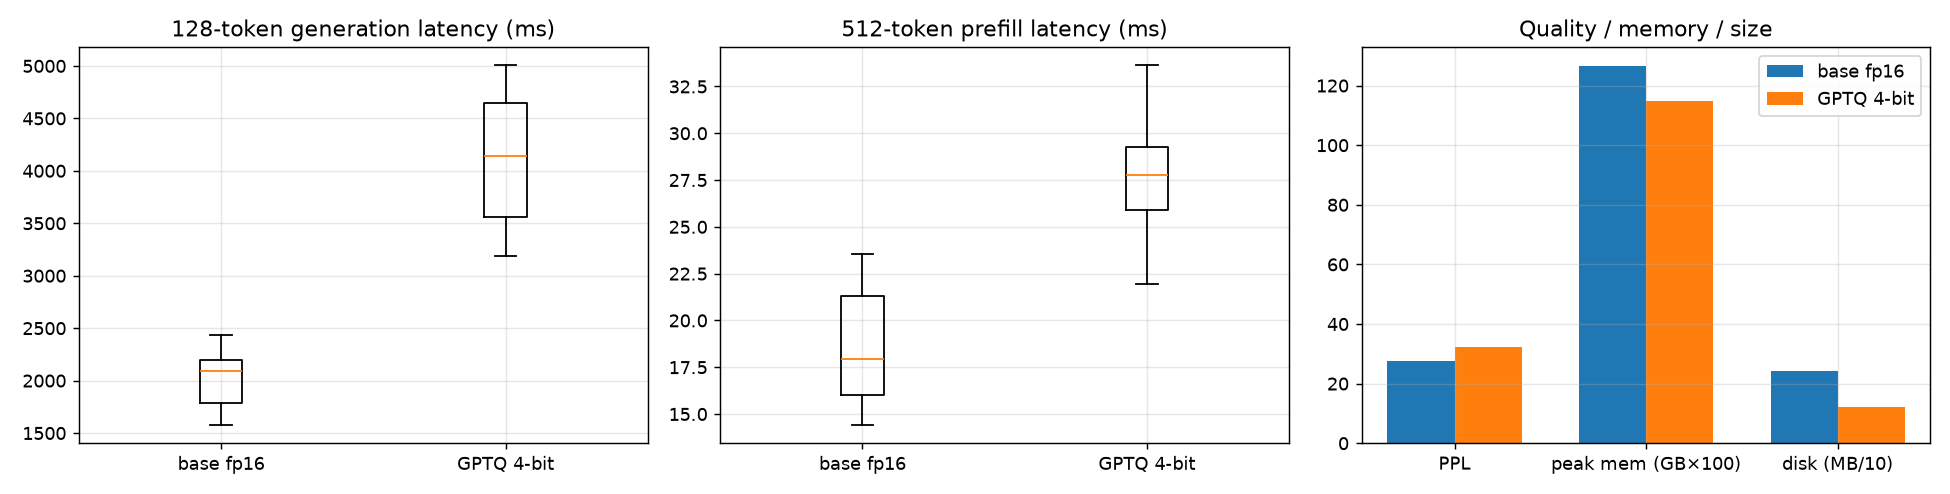

[2026-11-24 12:09:39] ===== Part 1 run finished =====


In [6]:
rows = [res_base, res_gptq]
tbl = pd.DataFrame({
    "Configuration": ["Base LLM (fp16)", "GPTQ-quantized LLM (4-bit)"],
    "Quality metric (WikiText-2 test PPL ↓ / eval loss)": [f"{r['ppl']:.2f} / {r['eval_loss']:.4f}" for r in rows],
    "p50 / p95 latency (ms) — 128-token generation": [f"{r['gen_p50_ms']:.1f} / {r['gen_p95_ms']:.1f}" for r in rows],
    "Peak memory (GB)": [f"{r['peak_mem_GB']:.3f}" for r in rows],
    "Size on disk (MB)": [f"{r['disk_MB']:.1f}" for r in rows]})
print("Table HW11.1 — GPTQ comparison on the same LLM/task"); display(tbl)

extra = pd.DataFrame([{k: r[k] for k in ("model", "quant_layers", "ppl", "eval_loss", "gen_p50_ms", "gen_p95_ms", "gen_tok_per_s",
                                          "prefill_p50_ms", "prefill_p95_ms", "load_mem_GB", "peak_mem_GB", "weights_MB", "disk_MB", "ppl_eval_time_s")} for r in rows])
print("\nDetailed measurements"); display(extra.round(4))
extra.to_csv(os.path.join(RES, "gptq_comparison.csv"), index=False)
d = lambda k: res_gptq[k] / res_base[k]
print(f"GPTQ / base:  PPL {d('ppl'):.3f}x (+{(res_gptq['ppl']-res_base['ppl']):.2f})  |  gen p50 {d('gen_p50_ms'):.2f}x  |  prefill p50 {d('prefill_p50_ms'):.2f}x  |  "
      f"weights-on-GPU {d('load_mem_GB'):.2f}x  |  peak mem {d('peak_mem_GB'):.2f}x  |  disk {d('disk_MB'):.2f}x")
json.dump(dict(model_id=MODEL_ID, revision=REVISION, gptq_config=dict(bits=4, group_size=128, desc_act=False, sym=True, dataset="wikitext2 (train)"),
               quant_time_s=quant_time, quant_peak_GB=quant_peak, eval=dict(windows=n_win, seq=SEQ, tokens=int(enc.shape[1])),
               base={k: v for k, v in res_base.items()}, gptq={k: v for k, v in res_gptq.items()},
               gpu=torch.cuda.get_device_name(0), torch=torch.__version__, transformers=transformers.__version__, gptqmodel=gptqmodel.__version__),
          open(os.path.join(RES, "summary.json"), "w"), indent=1, default=float)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = ["base fp16", "GPTQ 4-bit"]
ax[0].boxplot([res_base["gen_lat_ms"], res_gptq["gen_lat_ms"]], tick_labels=names); ax[0].set_title("128-token generation latency (ms)")
ax[1].boxplot([res_base["prefill_lat_ms"], res_gptq["prefill_lat_ms"]], tick_labels=names); ax[1].set_title("512-token prefill latency (ms)")
w = .35; xx = np.arange(3)
ax[2].bar(xx-w/2, [res_base["ppl"], res_base["peak_mem_GB"]*100, res_base["disk_MB"]/10], w, label="base fp16")
ax[2].bar(xx+w/2, [res_gptq["ppl"], res_gptq["peak_mem_GB"]*100, res_gptq["disk_MB"]/10], w, label="GPTQ 4-bit")
ax[2].set_xticks(xx); ax[2].set_xticklabels(["PPL", "peak mem (GB×100)", "disk (MB/10)"]); ax[2].legend(); ax[2].set_title("Quality / memory / size")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "p1_gptq_comparison.png"), dpi=130); plt.close()
display(Image(os.path.join(FIG, "p1_gptq_comparison.png")))
log("===== Part 1 run finished =====")

## 5. Findings — GPTQ (base vs. 4-bit, same WikiText-2 evaluation, same RTX 3060 Laptop GPU)

**Model:** `facebook/opt-125m` @ revision `27dcfa74d334bc871f3234de431e71c6eeba5dd6` (both runs).
**GPTQ:** 4-bit, group size 128, `desc_act=False`, symmetric. Calibrated on WikiText-2 *train* in **46.5 s** (peak 1.02 GB).
The kernel that runs at inference is GPT-QModel's `MarlinLinear`, used for all 72 decoder linear layers.

**Table HW11.1 — GPTQ comparison on the same LLM/task**

| Configuration | Quality metric (WikiText-2 test PPL / eval loss) | p50 / p95 latency (ms)¹ | Peak memory (GB)² | Size on disk (MB) |
|---|---|---|---|---|
| Base LLM (fp16) | 27.66 / 3.3198 | 2095.9 / 2426.9 | 1.265 | 242.3 |
| GPTQ-quantized LLM (4-bit) | 32.19 / 3.4718 | 4136.7 / 4858.1 | 1.148 | 122.7 |

¹ Batch 1, 32-token prompt → 128 new greedy tokens, 30 timed requests. For a single 512-token forward pass (prefill), p50 / p95 is
17.95 / 22.79 ms (base) vs 27.75 / 30.98 ms (GPTQ).
² Peak over perplexity evaluation and the latency runs. Resident weights right after loading: 0.233 GB (base) vs 0.116 GB (GPTQ).

**What the numbers say**
* **Quality:** perplexity rises from 27.66 to 32.19 (+4.54, +16 %). The eval loss rises by 0.152 nats/token. The base value matches the
  published fp16 figure (27.65), which validates the evaluation. A 4-bit cost of this size is typical for a model as small as 125M
  parameters; larger models lose much less.
* **Size:** on-disk size and resident weight memory both fall by about **2×**, not the 4× that "16 → 4 bit" suggests. GPTQ quantises only
  the linear layers (~85M parameters). The token embedding (50,272 × 768 ≈ 38.6M parameters, tied to the LM head), the positional
  embeddings and the LayerNorms stay fp16, and they are a large share of such a small model.
* **Peak memory** falls only 9 % (1.265 → 1.148 GB). For a 125M model the peak is set by activations, mainly the
  2048 × 50,272 logit tensor in the perplexity pass, not by weights. GPTQ only shrinks weights.
* **Latency gets worse:** generation is about 1.97× slower and prefill about 1.55× slower. At batch 1, a 125M model is bound by kernel launches and
  Python overhead, not by memory bandwidth. Each Marlin matmul adds on-the-fly dequantisation work, and the bandwidth saved on
  a 240 MB model is negligible on this GPU. GPTQ speedups appear when weight reads dominate: multi-billion-parameter models,
  memory-bound decoding, or VRAM limits that would otherwise force offloading.
* **Qualitative check:** both models continue the prompt fluently. The 4-bit model falls into repetition sooner, which is
  consistent with its higher perplexity.